<a href="https://colab.research.google.com/github/Varshini-213/skills-getting-started-with-github-copilot/blob/main/focus_tracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import json, requests, random
from google.colab import userdata

GROQ_API_KEY = userdata.get("GROQ_API_KEY")
MODEL = "openai/gpt-oss-120b"
print("Key loaded:", bool(GROQ_API_KEY))

In [23]:
DISTRACTING = {"youtube.com", "instagram.com", "facebook.com", "twitter.com", "x.com",
               "reddit.com", "netflix.com", "tiktok.com"}
PRODUCTIVE = {"github.com", "stackoverflow.com", "docs.google.com", "notion.so",
              "leetcode.com", "localhost"}

def category(domain):
    if any(domain.endswith(d) for d in DISTRACTING): return "distracting"
    if any(domain.endswith(d) for d in PRODUCTIVE): return "productive"
    return "neutral"

def label(score):
    if score >= 85: return "excellent"
    if score >= 70: return "good"
    if score >= 50: return "average"
    return "poor"

def analyze_session(segments, switches):
    total = sum(s["end"] - s["start"] for s in segments) / 1000 or 1
    idle = sum(s["end"] - s["start"] for s in segments if s["idle"]) / 1000
    cat_time = {"productive": 0, "neutral": 0, "distracting": 0}
    site_time = {}
    for s in segments:
        if s["idle"]:
            continue
        sec = (s["end"] - s["start"]) / 1000
        cat_time[category(s["domain"])] += sec
        site_time[s["domain"]] = site_time.get(s["domain"], 0) + sec

    p_distract = 50 * cat_time["distracting"] / total
    p_idle = 30 * idle / total
    p_switch = min(20, (switches / (total / 60)) * 4)
    score = round(max(0, 100 - p_distract - p_idle - p_switch))

    top = sorted(site_time.items(), key=lambda x: -x[1])[:5]
    return {
        "focus_score": score,
        "focus_level": label(score),
        "session_minutes": round(total / 60, 1),
        "tab_switches": switches,
        "idle_minutes": round(idle / 60, 1),
        "minutes_by_category": {k: round(v / 60, 1) for k, v in cat_time.items()},
        "top_sites_minutes": {k: round(v / 60, 1) for k, v in top},
        "penalties": {
            "distracting_sites": round(p_distract, 1),
            "idle": round(p_idle, 1),
            "tab_switches": round(p_switch, 1),
        },
    }

In [24]:
def get_llm_feedback(summary):
    prompt = f"""You are a productivity coach. Here is a focus session summary.
The score and level are already computed, do not change them.

How to read the data:
- "penalties" are POINTS deducted from a starting score of 100 (not minutes).
- "minutes_by_category" and "top_sites_minutes" are minutes spent.
- "neutral" time costs no points.

{json.dumps(summary)}

Reply with ONLY a JSON object in exactly this format, nothing else:
{{"explanation": "2-3 sentences on why the score dropped. Mention the biggest penalty first, in points, and back it up with minutes.",
  "recommendations": ["tip 1", "tip 2", "tip 3"]}}"""
    fallback = {"explanation": "AI explanation unavailable right now.",
                "recommendations": ["Close distracting tabs", "Stay on one task", "Take short breaks"]}
    try:
        r = requests.post(
            "https://api.groq.com/openai/v1/chat/completions",
            headers={"Authorization": f"Bearer {GROQ_API_KEY}"},
            json={"model": MODEL,
                  "messages": [{"role": "user", "content": prompt}],
                  "temperature": 0.4},
            timeout=60,
        )
        data = r.json()
        if "choices" not in data:
            print("Groq error:", data)
            return fallback
        text = data["choices"][0]["message"]["content"]
        text = text[text.find("{"): text.rfind("}") + 1]   # keep only the JSON part
        return json.loads(text)
    except Exception as e:
        print("LLM error:", repr(e))
        return fallback

def run_session(session):
    summary = analyze_session(session["segments"], session["switches"])
    return {**summary, **get_llm_feedback(summary)}

In [14]:
session = {
    "switches": 12,
    "segments": [
        {"domain": "github.com",  "idle": False, "start": 0,      "end": 300000},
        {"domain": "youtube.com", "idle": False, "start": 300000, "end": 600000},
        {"domain": "github.com",  "idle": True,  "start": 600000, "end": 720000},
    ],
}

result = run_session(session)
print(f"Focus score: {result['focus_score']}/100 ({result['focus_level']})\n")
print(result["explanation"], "\n")
for tip in result["recommendations"]:
    print("-", tip)
print("\nFull JSON:\n", json.dumps(result, indent=2))

Focus score: 70/100 (good)

The score fell because you spent equal time on productive and distracting sites (5 min each), and the penalties heavily impacted the total: 20.8 points for distracting sites, 5 points for idle time, and 4 points for frequent tab switches. These deductions outweighed the productive minutes, bringing the score down to 70. 

- Schedule short, intentional breaks to reduce idle time and avoid unnecessary tab switching.
- Block or limit access to high‑penalty sites like YouTube during work blocks.
- Group related tasks in a single tab or window to minimize context‑switching.

Full JSON:
 {
  "focus_score": 70,
  "focus_level": "good",
  "session_minutes": 12.0,
  "tab_switches": 12,
  "idle_minutes": 2.0,
  "minutes_by_category": {
    "productive": 5.0,
    "neutral": 0.0,
    "distracting": 5.0
  },
  "top_sites_minutes": {
    "github.com": 5.0,
    "youtube.com": 5.0
  },
  "penalties": {
    "distracting_sites": 20.8,
    "idle": 5.0,
    "tab_switches": 4.0


In [20]:
def fake_session(minutes=30):
    sites = ["github.com", "youtube.com", "stackoverflow.com",
             "instagram.com", "wikipedia.org", "reddit.com"]
    t, segs = 0, []
    while t < minutes * 60000:
        dur = random.randint(20, 240) * 1000
        segs.append({"domain": random.choice(sites), "idle": random.random() < 0.15,
                     "start": t, "end": t + dur})
        t += dur
    return {"segments": segs, "switches": len(segs)}

r = run_session(fake_session())
print(f"{r['focus_score']}/100 ({r['focus_level']})\n")
print(r["explanation"], "\n")
for tip in r["recommendations"]:
    print("-", tip)

70/100 (good)

The score dropped mainly due to the distracting sites penalty of 17.8 points, which came from 10.7 minutes spent on sites like YouTube and Reddit. Idle time added another 10.7 points loss, and frequent tab switches contributed an additional 1.7 points. 

- Block or limit access to high‑distraction sites during work periods.
- Schedule short, intentional breaks to reduce idle time and improve focus.
- Consolidate tasks to fewer tabs and use a single workspace to minimize tab switching.


In [21]:
demo_sessions = {
    "Excellent (expected)": {"switches": 3, "segments": [
        {"domain": "github.com",        "idle": False, "start": 0,      "end": 480000},
        {"domain": "stackoverflow.com", "idle": False, "start": 480000, "end": 600000}]},
    "Good (expected)": {"switches": 8, "segments": [
        {"domain": "github.com",  "idle": False, "start": 0,      "end": 420000},
        {"domain": "youtube.com", "idle": False, "start": 420000, "end": 540000},
        {"domain": "github.com",  "idle": True,  "start": 540000, "end": 600000}]},
    "Average (expected)": {"switches": 15, "segments": [
        {"domain": "github.com",  "idle": False, "start": 0,      "end": 240000},
        {"domain": "youtube.com", "idle": False, "start": 240000, "end": 480000},
        {"domain": "github.com",  "idle": True,  "start": 480000, "end": 600000}]},
    "Poor (expected)": {"switches": 40, "segments": [
        {"domain": "youtube.com",   "idle": False, "start": 0,      "end": 300000},
        {"domain": "instagram.com", "idle": False, "start": 300000, "end": 420000},
        {"domain": "youtube.com",   "idle": True,  "start": 420000, "end": 600000}]},
}

for name, s in demo_sessions.items():
    r = run_session(s)
    print("=" * 60)
    print(name, "->", f"{r['focus_score']}/100 ({r['focus_level']})")
    print(r["explanation"])
    for tip in r["recommendations"]:
        print("-", tip)

Excellent (expected) -> 99/100 (excellent)
The score dipped by 1.2 points, the only penalty incurred, due to 3 tab switches during the 10‑minute session. Frequent switching interrupts flow and costs points even though all time was spent on productive sites.
- Group related tasks and keep all necessary tabs open beforehand to minimize switching.
- Use a timer or Pomodoro technique to stay on one task for a set period before changing tabs.
- Close or mute non‑essential tabs and notifications to reduce the urge to switch.
Good (expected) -> 84/100 (good)
Your score dropped mainly because of the distracting sites penalty, which cost you 10 points for the 2 minutes spent on YouTube. Additional points were lost due to frequent tab switches (3.2 points for 8 switches) and idle time (3 points for 1 idle minute).
- Block or limit access to distracting sites during work sessions.
- Use a single-tab or focus mode to reduce unnecessary tab switching.
- Set a short timer to stay active and avoid id

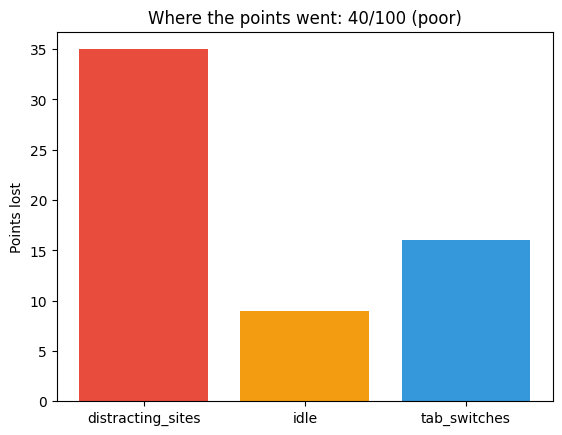

In [29]:
import matplotlib.pyplot as plt

r = run_session(demo_sessions["Poor (expected)"])
p = r["penalties"]
plt.bar(p.keys(), p.values(), color=["#e74c3c", "#f39c12", "#3498db"])
plt.title(f"Where the points went: {r['focus_score']}/100 ({r['focus_level']})")
plt.ylabel("Points lost")
plt.show()

In [28]:
import html
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, HTML, clear_output

BASE_DISTRACTING = {"youtube.com", "instagram.com", "facebook.com", "twitter.com",
                    "x.com", "reddit.com", "netflix.com", "tiktok.com"}
COLORS = {"excellent": "#2ecc71", "good": "#3498db", "average": "#f39c12", "poor": "#e74c3c"}

json_box = widgets.Textarea(
    placeholder="Paste the session JSON from the extension here",
    layout=widgets.Layout(width="100%", height="160px"))
extra_box = widgets.Text(
    value="web.whatsapp.com", description="Extra distracting sites:",
    placeholder="comma-separated, e.g. web.whatsapp.com, telegram.org",
    style={"description_width": "initial"}, layout=widgets.Layout(width="100%"))
analyze_btn = widgets.Button(description="Analyze", button_style="success", icon="play")
sample_btn = widgets.Button(description="Load sample", icon="file")
out = widgets.Output()

def on_sample(_):
    json_box.value = json.dumps({"switches": 12, "segments": [
        {"domain": "github.com",  "idle": False, "start": 0,      "end": 300000},
        {"domain": "youtube.com", "idle": False, "start": 300000, "end": 600000},
        {"domain": "github.com",  "idle": True,  "start": 600000, "end": 720000}]}, indent=1)

def on_analyze(_):
    with out:
        clear_output()
        try:
            session = json.loads(json_box.value)
            assert "segments" in session and "switches" in session
        except Exception as e:
            print("That JSON isn't valid. Copy it again from the extension.\nDetails:", e)
            return

        extras = {d.strip() for d in extra_box.value.split(",") if d.strip()}
        DISTRACTING.clear()
        DISTRACTING.update(BASE_DISTRACTING | extras)

        print("Analyzing...")
        r = run_session(session)
        clear_output()

        color = COLORS[r["focus_level"]]
        tips = "".join(f"<li>{html.escape(t)}</li>" for t in r["recommendations"])
        display(HTML(f"""
        <div style="border:2px solid {color};border-radius:12px;padding:16px;max-width:720px;font-family:sans-serif">
          <div style="font-size:44px;font-weight:bold;color:{color}">{r['focus_score']}<span style="font-size:20px">/100</span></div>
          <div style="font-size:20px;text-transform:uppercase;color:{color}">{r['focus_level']}</div>
          <p style="margin-top:12px">{html.escape(r['explanation'])}</p>
          <b>Recommendations</b><ul>{tips}</ul>
          <small>{r['session_minutes']} min session · {r['tab_switches']} tab switches · {r['idle_minutes']} min idle</small>
        </div>"""))

        fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
        p = r["penalties"]
        ax[0].bar(p.keys(), p.values(), color=["#e74c3c", "#f39c12", "#3498db"])
        ax[0].set_title("Points lost"); ax[0].tick_params(axis="x", rotation=15)
        c = r["minutes_by_category"]
        ax[1].bar(c.keys(), c.values(), color=["#2ecc71", "#95a5a6", "#e74c3c"])
        ax[1].set_title("Minutes by category (active time)")
        plt.tight_layout(); plt.show()

analyze_btn.on_click(on_analyze)
sample_btn.on_click(on_sample)

display(widgets.VBox([
    widgets.HTML("<h3>Focus Tracker</h3>"),
    json_box, extra_box,
    widgets.HBox([analyze_btn, sample_btn]),
    out]))